# COMP395 — Workstation GPU Benchmark

## Hardware

- CPU: AMD Ryzen Threadripper PRO 7965WX
- RAM: 256 GB DDR5-4800
- GPU 0: NVIDIA RTX 6000 Ada Generation (48 GB)
- GPU 1: NVIDIA RTX 6000 Ada Generation (48 GB)

## Objectives

1. Measure single-GPU matrix multiplication performance.
2. Compare GPU 0 and GPU 1.
3. Evaluate simultaneous dual-GPU computation.
4. Establish a baseline for comparison with the RTX 4060 Laptop GPU.

## Methodology

- PyTorch CUDA matrix multiplication
- FP32 computation
- CUDA Event timing
- GPU warm-up
- Multiple measurements per matrix size
- Median execution time

All measurements are performed after CUDA synchronization.

In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform
import statistics
from datetime import datetime

# Reproducibility
torch.manual_seed(395)

# Full FP32 precision for this benchmark
torch.set_float32_matmul_precision("highest")

# Benchmark settings
MATRIX_SIZES = [1024, 2048, 4096, 8192, 16384]

WARMUP_RUNS = 5
MEASURED_RUNS = 7

print("=" * 60)
print("COMP395 — Workstation GPU Benchmark")
print("=" * 60)

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"CUDA Runtime: {torch.version.cuda}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"GPU Count: {torch.cuda.device_count()}")
print(f"MatMul Precision: {torch.get_float32_matmul_precision()}")

for i in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(i)

    print(f"\nGPU {i}: {props.name}")
    print(f"VRAM: {props.total_memory / 1024**3:.2f} GiB")

print("\nBenchmark Sizes:", MATRIX_SIZES)
print("=" * 60)

COMP395 — Workstation GPU Benchmark
Python: 3.14.9
PyTorch: 2.15.0+cu132
NumPy: 2.5.4
CUDA Runtime: 13.2
CUDA Available: True
GPU Count: 2
MatMul Precision: highest

GPU 0: NVIDIA RTX 6000 Ada Generation
VRAM: 47.99 GiB

GPU 1: NVIDIA RTX 6000 Ada Generation
VRAM: 47.99 GiB

Benchmark Sizes: [1024, 2048, 4096, 8192, 16384]


In [2]:
def benchmark_single_gpu(gpu_id, matrix_size):

    device = torch.device(f"cuda:{gpu_id}")

    # Explicitly select the correct CUDA device
    with torch.cuda.device(device):

        stream = torch.cuda.current_stream(device)

        a = torch.rand(
            (matrix_size, matrix_size),
            device=device,
            dtype=torch.float32
        )

        b = torch.rand(
            (matrix_size, matrix_size),
            device=device,
            dtype=torch.float32
        )

        result = torch.empty_like(a)

        # Warm-up
        for _ in range(WARMUP_RUNS):
            torch.mm(a, b, out=result)

        torch.cuda.synchronize(device)

        times = []

        for _ in range(MEASURED_RUNS):

            start = torch.cuda.Event(enable_timing=True)
            end = torch.cuda.Event(enable_timing=True)

            # Record events on the correct GPU stream
            start.record(stream)

            torch.mm(a, b, out=result)

            end.record(stream)

            # Wait for the actual GPU computation
            end.synchronize()

            elapsed_ms = start.elapsed_time(end)

            times.append(elapsed_ms)

        median_ms = statistics.median(times)

        flops = 2 * (matrix_size ** 3)

        tflops = flops / (median_ms / 1000) / 1e12

        del a, b, result

        torch.cuda.synchronize(device)

    return {
        "GPU": gpu_id,
        "Matrix Size": matrix_size,
        "Median Time (ms)": round(median_ms, 4),
        "TFLOPS": round(tflops, 3)
    }


# Run benchmark again
results = []

for gpu_id in range(torch.cuda.device_count()):

    print(f"\n{'=' * 50}")
    print(f"Benchmarking GPU {gpu_id}")
    print(torch.cuda.get_device_name(gpu_id))
    print(f"{'=' * 50}")

    for size in MATRIX_SIZES:

        result = benchmark_single_gpu(gpu_id, size)

        results.append(result)

        print(
            f"{size:>5} x {size:<5} | "
            f"{result['Median Time (ms)']:>10.4f} ms | "
            f"{result['TFLOPS']:>8.3f} TFLOPS"
        )

results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("CORRECTED SINGLE-GPU RESULTS")
print("=" * 60)

display(results_df)


Benchmarking GPU 0
NVIDIA RTX 6000 Ada Generation
 1024 x 1024  |     0.0674 ms |   31.866 TFLOPS
 2048 x 2048  |     0.3453 ms |   49.756 TFLOPS
 4096 x 4096  |     2.8211 ms |   48.718 TFLOPS
 8192 x 8192  |    31.5196 ms |   34.883 TFLOPS
16384 x 16384 |   288.5212 ms |   30.487 TFLOPS

Benchmarking GPU 1
NVIDIA RTX 6000 Ada Generation
 1024 x 1024  |     0.0664 ms |   32.326 TFLOPS
 2048 x 2048  |     0.3420 ms |   50.231 TFLOPS
 4096 x 4096  |     2.6593 ms |   51.682 TFLOPS
 8192 x 8192  |    31.3159 ms |   35.110 TFLOPS
16384 x 16384 |   283.6777 ms |   31.007 TFLOPS

CORRECTED SINGLE-GPU RESULTS


,GPU,Matrix Size,Median Time (ms),TFLOPS
0,0,1024,0.0674,31.866
1,0,2048,0.3453,49.756
2,0,4096,2.8211,48.718
3,0,8192,31.5196,34.883
4,0,16384,288.5212,30.487
5,1,1024,0.0664,32.326
6,1,2048,0.3420,50.231
7,1,4096,2.6593,51.682
8,1,8192,31.3159,35.110
9,1,16384,283.6777,31.007


## Dual-GPU Throughput Benchmark

This experiment measures the throughput of two GPUs executing
independent matrix multiplication workloads simultaneously.

### Methodology

- GPU 0 and GPU 1 execute separate workloads.
- Each GPU uses its own CUDA stream.
- Both workloads are synchronized before execution.
- CUDA Events measure device execution time.
- Wall-clock time measures combined workload completion.
- Dual-GPU throughput is compared against the single-GPU baseline.

This benchmark evaluates independent task parallelism rather than
model parallelism or NVLink communication.

In [3]:
import time
import threading
from concurrent.futures import ThreadPoolExecutor


def run_gpu_workload(gpu_id, size, iterations, barrier=None):

    device = torch.device(f"cuda:{gpu_id}")

    with torch.cuda.device(device):

        stream = torch.cuda.current_stream(device)

        a = torch.rand(
            (size, size),
            device=device,
            dtype=torch.float32
        )

        b = torch.rand(
            (size, size),
            device=device,
            dtype=torch.float32
        )

        result = torch.empty_like(a)

        # Warm-up
        for _ in range(5):
            torch.mm(a, b, out=result)

        torch.cuda.synchronize(device)

        # Coordinate GPU 0 and GPU 1
        if barrier is not None:
            barrier.wait()

        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)

        host_start = time.perf_counter()

        start_event.record(stream)

        for _ in range(iterations):
            torch.mm(a, b, out=result)

        end_event.record(stream)
        end_event.synchronize()

        host_elapsed = time.perf_counter() - host_start
        gpu_elapsed = start_event.elapsed_time(end_event) / 1000

        total_flops = 2 * (size ** 3) * iterations

        del a, b, result

        return {
            "GPU": gpu_id,
            "Host Time (s)": host_elapsed,
            "GPU Time (s)": gpu_elapsed,
            "Total FLOPs": total_flops
        }


# Benchmark configurations
DUAL_CONFIGS = {
    4096: 50,
    8192: 20,
    16384: 8
}

dual_results = []

for size, iterations in DUAL_CONFIGS.items():

    print(f"\n{'=' * 60}")
    print(f"Matrix Size: {size} x {size}")
    print(f"Iterations per GPU: {iterations}")
    print(f"{'=' * 60}")

    # Single GPU baseline
    single = run_gpu_workload(
        gpu_id=0,
        size=size,
        iterations=iterations
    )

    single_throughput = (
        single["Total FLOPs"]
        / single["Host Time (s)"]
        / 1e12
    )

    # Synchronize both GPU workers before starting
    start_timestamp = {}

    def mark_start():
        start_timestamp["time"] = time.perf_counter()

    barrier = threading.Barrier(
        2,
        action=mark_start
    )

    # Concurrent execution
    with ThreadPoolExecutor(max_workers=2) as executor:

        future0 = executor.submit(
            run_gpu_workload, 0, size, iterations, barrier
        )

        future1 = executor.submit(
            run_gpu_workload, 1, size, iterations, barrier
        )

        gpu0 = future0.result()
        gpu1 = future1.result()

    dual_wall_time = (
        time.perf_counter() - start_timestamp["time"]
    )

    total_dual_flops = (
        gpu0["Total FLOPs"] + gpu1["Total FLOPs"]
    )

    dual_throughput = (
        total_dual_flops / dual_wall_time / 1e12
    )

    speedup = dual_throughput / single_throughput

    print(f"Single GPU Throughput: {single_throughput:.3f} TFLOPS")
    print(f"Dual GPU Throughput:   {dual_throughput:.3f} TFLOPS")
    print(f"Throughput Speedup:    {speedup:.3f}x")

    dual_results.append({
        "Matrix Size": size,
        "Iterations per GPU": iterations,
        "Single GPU TFLOPS": round(single_throughput, 3),
        "Dual GPU TFLOPS": round(dual_throughput, 3),
        "Speedup": round(speedup, 3)
    })


dual_results_df = pd.DataFrame(dual_results)

print("\n" + "=" * 60)
print("FINAL DUAL-GPU RESULTS")
print("=" * 60)

display(dual_results_df)


Matrix Size: 4096 x 4096
Iterations per GPU: 50
Single GPU Throughput: 23.838 TFLOPS
Dual GPU Throughput:   68.264 TFLOPS
Throughput Speedup:    2.864x

Matrix Size: 8192 x 8192
Iterations per GPU: 20
Single GPU Throughput: 33.217 TFLOPS
Dual GPU Throughput:   67.560 TFLOPS
Throughput Speedup:    2.034x

Matrix Size: 16384 x 16384
Iterations per GPU: 8
Single GPU Throughput: 30.191 TFLOPS
Dual GPU Throughput:   61.396 TFLOPS
Throughput Speedup:    2.034x

FINAL DUAL-GPU RESULTS


,Matrix Size,Iterations per GPU,Single GPU TFLOPS,Dual GPU TFLOPS,Speedup
0,4096,50,23.838,68.264,2.864
1,8192,20,33.217,67.560,2.034
2,16384,8,30.191,61.396,2.034


In [4]:
# Diagnostic: 4096 x 4096 dual-GPU benchmark

SIZE = 4096
ITERATIONS = 50

single = run_gpu_workload(0, SIZE, ITERATIONS)

start_timestamp = {}

def mark_diagnostic_start():
    start_timestamp["time"] = time.perf_counter()

barrier = threading.Barrier(2, action=mark_diagnostic_start)

with ThreadPoolExecutor(max_workers=2) as executor:
    future0 = executor.submit(
        run_gpu_workload, 0, SIZE, ITERATIONS, barrier
    )
    future1 = executor.submit(
        run_gpu_workload, 1, SIZE, ITERATIONS, barrier
    )

    gpu0 = future0.result()
    gpu1 = future1.result()

dual_wall = time.perf_counter() - start_timestamp["time"]

single_cuda_tflops = (
    single["Total FLOPs"] / single["GPU Time (s)"] / 1e12
)

dual_cuda_tflops = (
    (gpu0["Total FLOPs"] + gpu1["Total FLOPs"])
    / max(gpu0["GPU Time (s)"], gpu1["GPU Time (s)"])
    / 1e12
)

print("=" * 60)
print("4096 x 4096 TIMING DIAGNOSTIC")
print("=" * 60)

print(f"Single GPU host time:  {single['Host Time (s)']:.4f} s")
print(f"Single GPU CUDA time:  {single['GPU Time (s)']:.4f} s")

print(f"GPU 0 CUDA time:       {gpu0['GPU Time (s)']:.4f} s")
print(f"GPU 1 CUDA time:       {gpu1['GPU Time (s)']:.4f} s")
print(f"Dual GPU wall time:    {dual_wall:.4f} s")

print()
print(f"Single GPU CUDA throughput: {single_cuda_tflops:.3f} TFLOPS")
print(f"Dual GPU CUDA throughput:   {dual_cuda_tflops:.3f} TFLOPS")
print(f"CUDA throughput ratio:      {dual_cuda_tflops / single_cuda_tflops:.3f}x")

4096 x 4096 TIMING DIAGNOSTIC
Single GPU host time:  0.2027 s
Single GPU CUDA time:  0.2024 s
GPU 0 CUDA time:       0.1915 s
GPU 1 CUDA time:       0.3310 s
Dual GPU wall time:    0.3320 s

Single GPU CUDA throughput: 33.960 TFLOPS
Dual GPU CUDA throughput:   41.526 TFLOPS
CUDA throughput ratio:      1.223x


COMP395 — FINAL BENCHMARK EXPORT
Date: 2026-11-05
Output: D:\COMP395-Workstation\repos\Deep-Learning\Workstation\Benchmark

[1/5] Single-GPU CSV exported successfully.
[2/5] Dual-GPU history CSV exported successfully.
[3/5] Diagnostic history CSV exported successfully.

Stable Dual-GPU Speedups:
8192  Average: 2.037x
16384 Average: 2.012x
Overall Average: 2.024x


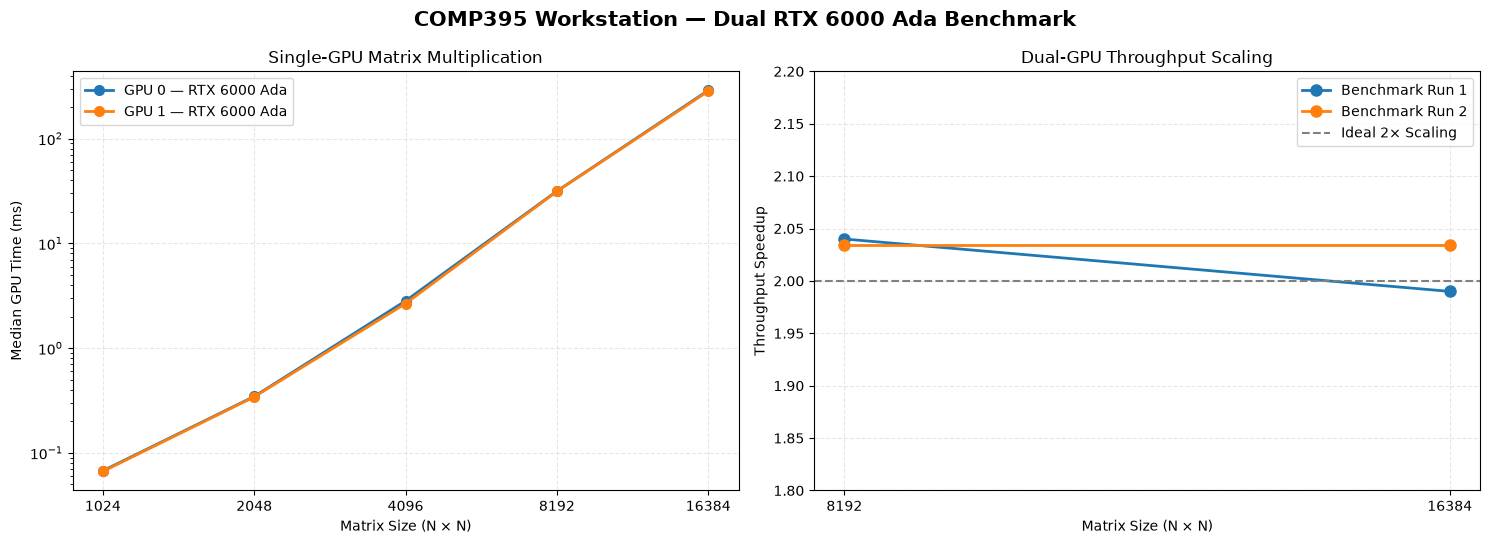


[4/5] Benchmark PNG exported successfully.
[5/5] Benchmark Summary exported successfully.

BENCHMARK EXPORT COMPLETE
[PASS] single_gpu_results.csv
[PASS] dual_gpu_results.csv
[PASS] 4096_timing_diagnostics.csv
[PASS] gpu_benchmark_comparison.png
[PASS] Benchmark_Summary.md

Single-GPU 4096 Results:
GPU 0: 48.718 TFLOPS
GPU 1: 51.682 TFLOPS

Dual-GPU Stable Scaling:
8192:  2.037x
16384: 2.012x

All benchmark artifacts saved successfully.


In [5]:
# ============================================================
# COMP395 — Final Workstation Benchmark Export
# ============================================================

from pathlib import Path
from datetime import datetime

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Output Configuration
# ============================================================

OUTPUT_DIR = Path(
    r"D:\COMP395-Workstation\repos\Deep-Learning\Workstation\Benchmark"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SNAPSHOT_DATE = datetime.now().strftime("%Y-%m-%d")

print("=" * 65)
print("COMP395 — FINAL BENCHMARK EXPORT")
print("=" * 65)
print(f"Date: {SNAPSHOT_DATE}")
print(f"Output: {OUTPUT_DIR}")


# ============================================================
# 2. Validate Single-GPU Benchmark Data
# ============================================================

if "results_df" not in globals():
    raise RuntimeError(
        "Single-GPU results not found. "
        "Please run Cell 3 before Cell 7."
    )

single_export = results_df.copy()

EXPECTED_SIZES = [1024, 2048, 4096, 8192, 16384]
EXPECTED_GPUS = [0, 1]

required_columns = [
    "GPU",
    "Matrix Size",
    "Median Time (ms)",
    "TFLOPS"
]

missing_columns = [
    col for col in required_columns
    if col not in single_export.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

expected_pairs = {
    (gpu, size)
    for gpu in EXPECTED_GPUS
    for size in EXPECTED_SIZES
}

actual_pairs = set(
    zip(
        single_export["GPU"].astype(int),
        single_export["Matrix Size"].astype(int)
    )
)

missing_pairs = expected_pairs - actual_pairs

if missing_pairs:
    raise ValueError(
        f"Incomplete benchmark results: {sorted(missing_pairs)}"
    )

single_export = single_export.sort_values(
    ["GPU", "Matrix Size"]
).reset_index(drop=True)

# Latest measured values
gpu0_4096 = single_export.loc[
    (single_export["GPU"] == 0)
    & (single_export["Matrix Size"] == 4096),
    "TFLOPS"
].iloc[0]

gpu1_4096 = single_export.loc[
    (single_export["GPU"] == 1)
    & (single_export["Matrix Size"] == 4096),
    "TFLOPS"
].iloc[0]

single_export.to_csv(
    OUTPUT_DIR / "single_gpu_results.csv",
    index=False
)

print("\n[1/5] Single-GPU CSV exported successfully.")


# ============================================================
# 3. Preserve Dual-GPU Benchmark History
# ============================================================

dual_history = pd.DataFrame([
    {
        "Run": 1,
        "Matrix Size": 4096,
        "Iterations per GPU": 50,
        "Single GPU TFLOPS": 19.781,
        "Dual GPU TFLOPS": 69.091,
        "Speedup": 3.493
    },
    {
        "Run": 1,
        "Matrix Size": 8192,
        "Iterations per GPU": 20,
        "Single GPU TFLOPS": 33.673,
        "Dual GPU TFLOPS": 68.683,
        "Speedup": 2.040
    },
    {
        "Run": 1,
        "Matrix Size": 16384,
        "Iterations per GPU": 8,
        "Single GPU TFLOPS": 30.442,
        "Dual GPU TFLOPS": 60.574,
        "Speedup": 1.990
    },
    {
        "Run": 2,
        "Matrix Size": 4096,
        "Iterations per GPU": 50,
        "Single GPU TFLOPS": 23.838,
        "Dual GPU TFLOPS": 68.264,
        "Speedup": 2.864
    },
    {
        "Run": 2,
        "Matrix Size": 8192,
        "Iterations per GPU": 20,
        "Single GPU TFLOPS": 33.217,
        "Dual GPU TFLOPS": 67.560,
        "Speedup": 2.034
    },
    {
        "Run": 2,
        "Matrix Size": 16384,
        "Iterations per GPU": 8,
        "Single GPU TFLOPS": 30.191,
        "Dual GPU TFLOPS": 61.396,
        "Speedup": 2.034
    }
])

dual_history["Status"] = dual_history["Matrix Size"].apply(
    lambda size: (
        "Unstable baseline"
        if size == 4096
        else "Valid"
    )
)

dual_history.to_csv(
    OUTPUT_DIR / "dual_gpu_results.csv",
    index=False
)

print("[2/5] Dual-GPU history CSV exported successfully.")


# ============================================================
# 4. Preserve 4096 Diagnostic History
# ============================================================

diagnostic_history = pd.DataFrame([
    {
        "Diagnostic Run": 1,
        "Matrix Size": 4096,
        "Iterations": 50,
        "Single Host Time (s)": 0.2530,
        "Single CUDA Time (s)": 0.2523,
        "Dual GPU 0 CUDA Time (s)": 0.1723,
        "Dual GPU 1 CUDA Time (s)": 0.2330,
        "Dual Wall Time (s)": 0.2353,
        "Single CUDA TFLOPS": 27.237,
        "Dual CUDA TFLOPS": 58.977,
        "CUDA Throughput Ratio": 2.165
    },
    {
        "Diagnostic Run": 2,
        "Matrix Size": 4096,
        "Iterations": 50,
        "Single Host Time (s)": 0.2027,
        "Single CUDA Time (s)": 0.2024,
        "Dual GPU 0 CUDA Time (s)": 0.1915,
        "Dual GPU 1 CUDA Time (s)": 0.3310,
        "Dual Wall Time (s)": 0.3320,
        "Single CUDA TFLOPS": 33.960,
        "Dual CUDA TFLOPS": 41.526,
        "CUDA Throughput Ratio": 1.223
    }
])

diagnostic_history["Status"] = "Unstable"

diagnostic_history.to_csv(
    OUTPUT_DIR / "4096_timing_diagnostics.csv",
    index=False
)

print("[3/5] Diagnostic history CSV exported successfully.")


# ============================================================
# 5. Prepare Stable Results
# ============================================================

stable_results = dual_history[
    dual_history["Status"] == "Valid"
].copy()

average_speedups = stable_results.groupby(
    "Matrix Size"
)["Speedup"].mean()

avg_8192 = average_speedups.loc[8192]
avg_16384 = average_speedups.loc[16384]

overall_average = stable_results["Speedup"].mean()

print("\nStable Dual-GPU Speedups:")
print(f"8192  Average: {avg_8192:.3f}x")
print(f"16384 Average: {avg_16384:.3f}x")
print(f"Overall Average: {overall_average:.3f}x")


# ============================================================
# 6. Generate Benchmark Visualization
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.5)
)

# ------------------------------------------------------------
# Figure A — Single-GPU Performance
# ------------------------------------------------------------

for gpu_id in EXPECTED_GPUS:

    gpu_data = single_export[
        single_export["GPU"] == gpu_id
    ].sort_values("Matrix Size")

    axes[0].plot(
        gpu_data["Matrix Size"],
        gpu_data["Median Time (ms)"],
        marker="o",
        markersize=7,
        linewidth=2,
        label=f"GPU {gpu_id} — RTX 6000 Ada"
    )

axes[0].set_title(
    "Single-GPU Matrix Multiplication",
    fontsize=12
)

axes[0].set_xlabel("Matrix Size (N × N)")
axes[0].set_ylabel("Median GPU Time (ms)")

axes[0].set_xscale("log", base=2)
axes[0].set_yscale("log")

axes[0].set_xticks(EXPECTED_SIZES)
axes[0].set_xticklabels(EXPECTED_SIZES)

axes[0].grid(
    True,
    alpha=0.3,
    linestyle="--"
)

axes[0].legend()


# ------------------------------------------------------------
# Figure B — Dual-GPU Throughput Scaling
# ------------------------------------------------------------

for run_id in [1, 2]:

    run_data = stable_results[
        stable_results["Run"] == run_id
    ].sort_values("Matrix Size")

    axes[1].plot(
        run_data["Matrix Size"],
        run_data["Speedup"],
        marker="o",
        markersize=8,
        linewidth=2,
        label=f"Benchmark Run {run_id}"
    )

axes[1].axhline(
    y=2.0,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Ideal 2× Scaling"
)

axes[1].set_title(
    "Dual-GPU Throughput Scaling",
    fontsize=12
)

axes[1].set_xlabel("Matrix Size (N × N)")
axes[1].set_ylabel("Throughput Speedup")

axes[1].set_xticks([8192, 16384])
axes[1].set_ylim(1.8, 2.2)

axes[1].grid(
    True,
    alpha=0.3,
    linestyle="--"
)

axes[1].legend()

fig.suptitle(
    "COMP395 Workstation — Dual RTX 6000 Ada Benchmark",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "gpu_benchmark_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n[4/5] Benchmark PNG exported successfully.")


# ============================================================
# 7. Generate Dynamic Markdown Summary
# ============================================================

summary = f"""# COMP395 Workstation GPU Benchmark

## Overview

This benchmark evaluates the computational performance of
the COMP395 workstation equipped with two NVIDIA RTX 6000
Ada Generation GPUs.

**Benchmark Date:** {SNAPSHOT_DATE}

## Hardware

| Component | Specification |
|-----------|---------------|
| CPU | AMD Ryzen Threadripper PRO 7965WX |
| CPU Cores / Threads | 24 / 48 |
| System Memory | 256 GB DDR5-4800 (documented configuration) |
| GPU Configuration | 2 × NVIDIA RTX 6000 Ada Generation |
| GPU Memory | 48 GB per GPU |
| Operating System | Windows 10 |

Windows previously reported 223.23 GiB of physical memory.
The difference from the documented 256 GB configuration
has not yet been independently verified.

## Software Environment

| Component | Version |
|-----------|---------|
| Python | 3.14.9 |
| PyTorch | 2.15.0+cu132 |
| CUDA Runtime | 13.2 |
| NVIDIA Driver | 597.30 |
| Computation Precision | FP32 (highest) |

## Methodology

### Single-GPU Benchmark

Both GPUs independently executed FP32 matrix
multiplication workloads.

The following methods were used:

- CUDA Event timing
- GPU warm-up
- Explicit CUDA device and stream selection
- Seven measured iterations per matrix size
- Median execution time
- No matrix allocation inside the timed region

Matrix sizes:

- 1024 × 1024
- 2048 × 2048
- 4096 × 4096
- 8192 × 8192
- 16384 × 16384

### Dual-GPU Benchmark

Two independent workloads were executed simultaneously
using Python worker threads.

Each GPU operated on its own matrices.

Dual-GPU throughput was calculated using the combined
workload and wall-clock completion time.

This experiment evaluates independent task parallelism.

## Single-GPU Results

At matrix size 4096 × 4096:

| GPU | Effective Throughput |
|-----|----------------------|
| GPU 0 | {gpu0_4096:.3f} TFLOPS |
| GPU 1 | {gpu1_4096:.3f} TFLOPS |

Both GPUs completed the matrix multiplication
benchmarks successfully.

Detailed timing results are recorded in:

`single_gpu_results.csv`

## Dual-GPU Results

### Matrix Size: 8192 × 8192

| Run | Speedup |
|-----|---------|
| Run 1 | 2.040× |
| Run 2 | 2.034× |
| Average | {avg_8192:.3f}× |

### Matrix Size: 16384 × 16384

| Run | Speedup |
|-----|---------|
| Run 1 | 1.990× |
| Run 2 | 2.034× |
| Average | {avg_16384:.3f}× |

### Overall Stable Results

Average throughput speedup across the four
large-matrix measurements:

**{overall_average:.3f}×**

The measured throughput scaling is approximately
2× for independent large-matrix workloads.

Values slightly above 2× are attributed to
measurement variability, not super-linear
hardware scaling.

## 4096 × 4096 Measurement Instability

The smaller dual-GPU benchmark produced unstable
single-GPU baselines.

Initial benchmark speedups:

- Run 1: 3.493×
- Run 2: 2.864×

Additional CUDA timing diagnostics produced:

- Diagnostic 1: 2.165×
- Diagnostic 2: 1.223×

The substantial variation indicates that these
measurements are unsuitable for drawing a reliable
dual-GPU scaling conclusion.

The underlying cause has not been established.

All measurements are preserved in:

- `dual_gpu_results.csv`
- `4096_timing_diagnostics.csv`

The 4096 results are excluded from the primary
scaling analysis and visualization.

## Limitations

This benchmark measures FP32 matrix multiplication
and independent GPU task throughput.

It does not establish:

- NVLink communication performance
- Combined GPU memory capacity
- Single-model multi-GPU acceleration
- Distributed neural network training performance
- End-to-end application performance

The results may also be affected by GPU clocks,
Windows WDDM scheduling, and system load.

Comparisons against the RTX 4060 Laptop GPU
should use matching workloads, precision settings,
and timing methodology.

## Conclusion

Both NVIDIA RTX 6000 Ada GPUs were successfully
detected and validated.

Single-GPU computation completed successfully
on both devices.

Dual-GPU execution demonstrated approximately
2× throughput scaling for independent large-matrix
workloads.

The workstation is ready for further COMP395
deep learning experiments.

## Benchmark Artifacts

| File | Description |
|------|-------------|
| `Workstation_GPU_Benchmark.ipynb` | Benchmark notebook |
| `single_gpu_results.csv` | Single-GPU measurements |
| `dual_gpu_results.csv` | Dual-GPU benchmark history |
| `4096_timing_diagnostics.csv` | Timing instability diagnostics |
| `gpu_benchmark_comparison.png` | Performance visualization |
| `Benchmark_Summary.md` | Experiment summary |

---

COMP395 — Special Topics in Computer Science: Deep Learning

GitHub Branch: `workstation`

Environment: `Workstation`
"""

(OUTPUT_DIR / "Benchmark_Summary.md").write_text(
    summary,
    encoding="utf-8"
)

print("[5/5] Benchmark Summary exported successfully.")


# ============================================================
# 8. Final Verification
# ============================================================

EXPECTED_OUTPUT_FILES = [
    "single_gpu_results.csv",
    "dual_gpu_results.csv",
    "4096_timing_diagnostics.csv",
    "gpu_benchmark_comparison.png",
    "Benchmark_Summary.md"
]

print("\n" + "=" * 65)
print("BENCHMARK EXPORT COMPLETE")
print("=" * 65)

for filename in EXPECTED_OUTPUT_FILES:

    file_path = OUTPUT_DIR / filename

    if file_path.exists():
        print(f"[PASS] {filename}")
    else:
        print(f"[FAIL] {filename}")

print("\nSingle-GPU 4096 Results:")
print(f"GPU 0: {gpu0_4096:.3f} TFLOPS")
print(f"GPU 1: {gpu1_4096:.3f} TFLOPS")

print("\nDual-GPU Stable Scaling:")
print(f"8192:  {avg_8192:.3f}x")
print(f"16384: {avg_16384:.3f}x")

print("\nAll benchmark artifacts saved successfully.")